In [1]:
'''Apply exhaustive Grid Search techniques across multiple hyperparameters and
 models to find the best-performing configurations for predicting applicant admission outcomes.'''

'Apply exhaustive Grid Search techniques across multiple hyperparameters and\n models to find the best-performing configurations for predicting applicant admission outcomes.'

In [2]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
# loading dataset
df = pd.read_csv('Adm.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:
# displaying dataset summary and check for null values
print(df.info())
print(df.describe())
print('Missing values:', df.isnull().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB
None
        Serial No.    GRE Score  TOEFL Score  University Rating          SOP  \
count  1000.000000  1000.000000 

In [5]:
# selecting predictive features and admission target
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Chance of Admit']
print(X.shape, y.shape)

(1000, 7) (1000,)


In [6]:
# splitting data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
# standardizing feature distributions
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
# defining hyperparameter grids for multiple models
models_and_grids = {
    'Ridge': {
        'model': Ridge(),
        'params': {
            'alpha': [0.01, 0.1, 1.0, 10.0, 50.0],
            'solver': ['auto', 'svd', 'cholesky']
        }
    },
    'ElasticNet': {
        'model': ElasticNet(random_state=42),
        'params': {
            'alpha': [0.001, 0.01, 0.1, 1.0],
            'l1_ratio': [0.2, 0.5, 0.8]
        }
    },
    'Decision Tree': {
        'model': DecisionTreeRegressor(random_state=42),
        'params': {
            'max_depth': [3, 5, 7, 10],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4]
        }
    },
    'Random Forest': {
        'model': RandomForestRegressor(random_state=42),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [5, 7, 10],
            'min_samples_split': [2, 5],
            'min_samples_leaf': [1, 2]
        }
    }
}

In [9]:
# executing exhaustive grid search with cross validation
grid_searches = {}
for name, config in models_and_grids.items():
    print('Searching:', name)
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=5,
        scoring='r2',
        n_jobs=-1
    )
    grid.fit(X_train_scaled, y_train)
    grid_searches[name] = grid
print('All grid searches completed successfully!')

Searching: Ridge


Searching: ElasticNet
Searching: Decision Tree


Searching: Random Forest


All grid searches completed successfully!


In [10]:
# extracting best parameters and cross validation scores
best_cv_summary = []
for name, grid in grid_searches.items():
    best_cv_summary.append({
        'Model': name,
        'Best CV R2': grid.best_score_,
        'Best Parameters': grid.best_params_
    })

cv_df = pd.DataFrame(best_cv_summary)
print(cv_df.to_string(index=False))

        Model  Best CV R2                                                                       Best Parameters
        Ridge    0.948161                                                      {'alpha': 1.0, 'solver': 'auto'}
   ElasticNet    0.948154                                                     {'alpha': 0.001, 'l1_ratio': 0.2}
Decision Tree    0.853904                      {'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 10}
Random Forest    0.914956 {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [11]:
# evaluating best models on unseen test data
test_eval_summary = []
for name, grid in grid_searches.items():
    best_estimator = grid.best_estimator_
    y_pred = best_estimator.predict(X_test_scaled)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    test_eval_summary.append({
        'Model': name,
        'CV Best R2': grid.best_score_,
        'Test R2': r2,
        'Test RMSE': rmse,
        'Test MAE': mae,
        'Best Configuration': grid.best_params_
    })

comparison_df = pd.DataFrame(test_eval_summary)
print(comparison_df.to_string(index=False))

        Model  CV Best R2  Test R2  Test RMSE  Test MAE                                                                    Best Configuration
        Ridge    0.948161 0.940710   0.024638  0.019574                                                      {'alpha': 1.0, 'solver': 'auto'}
   ElasticNet    0.948154 0.940656   0.024649  0.019583                                                     {'alpha': 0.001, 'l1_ratio': 0.2}
Decision Tree    0.853904 0.831012   0.041594  0.033103                      {'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 10}
Random Forest    0.914956 0.907832   0.030718  0.023505 {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [12]:
# inspecting top grid search candidates for random forest
rf_cv_results = pd.DataFrame(grid_searches['Random Forest'].cv_results_)
top_rf_configs = rf_cv_results[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
top_rf_configs = top_rf_configs.sort_values(by='rank_test_score').head(5)
print(top_rf_configs.to_string(index=False))

                                                                               params  mean_test_score  std_test_score  rank_test_score
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}         0.914956        0.007373                1
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}         0.914460        0.007724                2
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}         0.913609        0.009013                3
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}         0.913162        0.008921                4
 {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}         0.912670        0.008150                5


In [13]:
# identifying overall best performing model configuration
overall_best_idx = comparison_df['Test R2'].idxmax()
overall_best = comparison_df.loc[overall_best_idx]
print('Winning Model:', overall_best['Model'])
print('Winning Config:', overall_best['Best Configuration'])
print('Test R2:', overall_best['Test R2'])
print('Test RMSE:', overall_best['Test RMSE'])

Winning Model: Ridge
Winning Config: {'alpha': 1.0, 'solver': 'auto'}
Test R2: 0.9407097029705774
Test RMSE: 0.02463765534679036


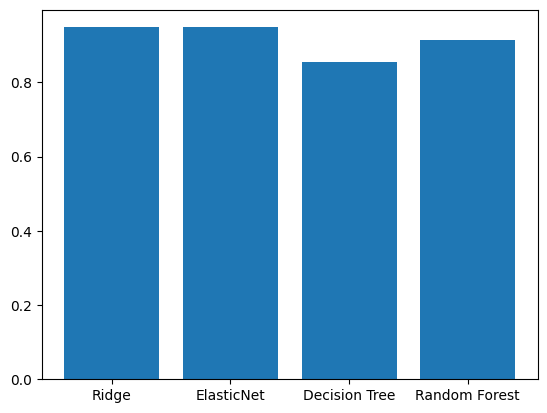

In [14]:
# plotting cross validation r2 scores across models
plt.bar(comparison_df['Model'], comparison_df['CV Best R2'])
plt.show()

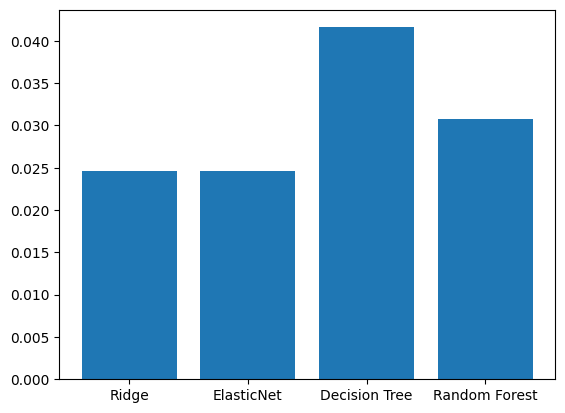

In [15]:
# plotting test rmse across best model configurations
plt.bar(comparison_df['Model'], comparison_df['Test RMSE'])
plt.show()

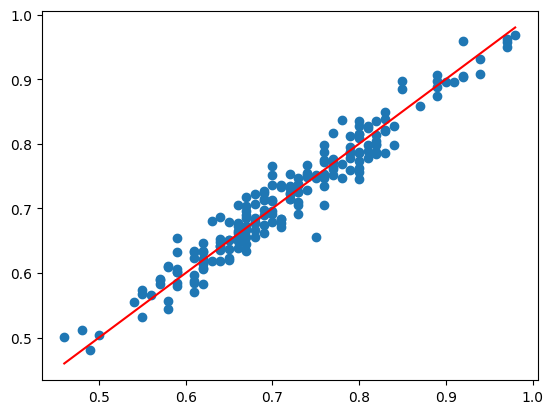

In [16]:
# plotting actual vs predicted values for overall best configuration
winning_model = grid_searches[overall_best['Model']].best_estimator_
y_pred_winning = winning_model.predict(X_test_scaled)
plt.scatter(y_test, y_pred_winning)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.show()

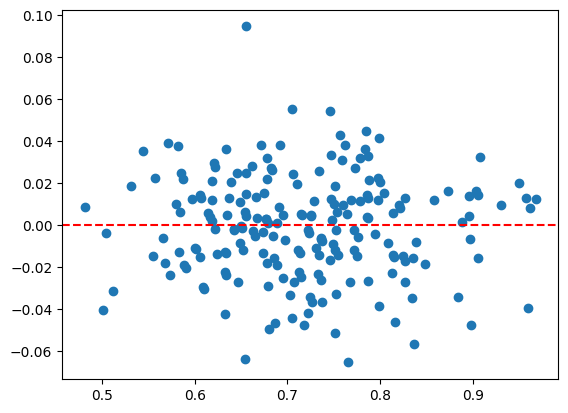

In [17]:
# plotting residuals of best model configuration
resids = y_test - y_pred_winning
plt.scatter(y_pred_winning, resids)
plt.axhline(0, color='red', linestyle='--')
plt.show()